In [1]:
# Test get_country_fields
from pathlib import Path
import sys
print(sys.executable)

# Identify project root
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

# Add project root to Python's module search path
sys.path.insert(0, str(PROJECT_ROOT))
from src.utils import get_country_fields

france_path = get_country_fields("FR", "France", "data")
kenya_path = get_country_fields("KE", "Kenya", "data")

/Users/robmoore/geoanalytics/geog313-assignments/assignment-7/.pixi/envs/default/bin/python
File already exists: data/FR_France.parquet. Skipping download.
File already exists: data/KE_Kenya.parquet. Skipping download.


In [2]:
# test load_fields
from src.utils import load_fields
# test load fields
france = load_fields(france_path)
kenya = load_fields(kenya_path)

print(type(france))
print(france.npartitions)
print(france.crs)
print(france.head())

<class 'dask_geopandas.expr.GeoDataFrame'>
81
OGC:CRS84
   metrics:area  metrics:perimeter      id    determination:datetime  \
0   4113.355957         353.254486  279745 2024-01-01 00:00:00+00:00   
1  30344.457031        1413.280151  279804 2024-01-01 00:00:00+00:00   
2  53741.164062        1279.683472  279803 2025-01-01 00:00:00+00:00   
3    567.141357         102.505760  279746 2024-01-01 00:00:00+00:00   
4   1843.065308         213.442795  279749 2024-01-01 00:00:00+00:00   

  determination:method                                           geometry  \
0         auto-imagery  POLYGON ((-1.22082 44.82727, -1.22082 44.82718...   
1         auto-imagery  POLYGON ((-1.13998 44.84659, -1.13998 44.8465,...   
2         auto-imagery  POLYGON ((-1.13962 44.84668, -1.13962 44.84659...   
3         auto-imagery  POLYGON ((-1.21373 44.84937, -1.21373 44.84928...   
4         auto-imagery  POLYGON ((-1.2087 44.85404, -1.2087 44.85395, ...   

                                                

In [3]:
# test verify_area
from src.utils import verify_area

#inspect a small sample of France
sample = france.head(10)

# check its original CRS
print(sample.crs)

# estimate a suitable UTM projection
target_crs = sample.estimate_utm_crs()

# reproject the sample
projected = sample.to_crs(target_crs)

# calculate area in square meters
calculated_area = projected.geometry.area

# compare against the original area values
print(sample["metrics:area"])
print(calculated_area)

# finally, test your utility function
comparison = verify_area(france, n=10)
print(comparison)


OGC:CRS84
0     4113.355957
1    30344.457031
2    53741.164062
3      567.141357
4     1843.065308
5      496.194550
6      425.312500
7      496.205170
8     4962.011719
9      141.770065
Name: metrics:area, dtype: float32
0     4112.066706
1    30336.302261
2    53726.745349
3      566.965609
4     1842.499112
5      496.042403
6      425.180836
7      496.052412
8     4960.479811
9      141.726132
dtype: float64
   computed_area  metrics:area
0    4112.066706   4113.355957
1   30336.302261  30344.457031
2   53726.745349  53741.164062
3     566.965609    567.141357
4    1842.499112   1843.065308
5     496.042403    496.194550
6     425.180836    425.312500
7     496.052412    496.205170
8    4960.479811   4962.011719
9     141.726132    141.770065


In [4]:
from src.utils import field_area_distribution
france_areas = field_area_distribution(france)
print(type(france_areas))
print(france_areas.head())

<class 'dask.dataframe.dask_expr._collection.Series'>
0     4113.355957
1    30344.457031
2    53741.164062
3      567.141357
4     1843.065308
Name: metrics:area, dtype: float32


In [5]:
# Load France and Kenya for a single chosen year, and report the number of fields in each.

france_path = get_country_fields("FR", "France", "data")
kenya_path = get_country_fields("KE", "Kenya", "data")

# load laxy dask gdf
france = load_fields(france_path)
kenya = load_fields(kenya_path)

# filter to 2024
france24 = france[france["determination:datetime"].dt.year == 2024]
kenya24 = kenya[kenya["determination:datetime"].dt.year == 2024]

france_shape = france24.shape[0].compute()
kenya_shape = kenya24.shape[0].compute()

print("France:", france_shape)
print("Kenya:", kenya_shape)

    

File already exists: data/FR_France.parquet. Skipping download.
File already exists: data/KE_Kenya.parquet. Skipping download.
France: 2644254
Kenya: 12964056


In [6]:
# take small sample of france 2024 and check crs
sample = france24.head()
print(sample.crs)

# calculate area without reprojecting
area_degrees = sample.geometry.area
print(area_degrees)

OGC:CRS84
0    4.680394e-07
1    3.453808e-06
3    6.455715e-08
4    2.098107e-07
5    5.648751e-08
dtype: float64


/var/folders/j1/0_sk538d7d98b54ykvvght1h0000gn/T/ipykernel_8718/329978490.py:6: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  area_degrees = sample.geometry.area


In [7]:
# Estimate appropriate UTM CRS
target_crs = sample.estimate_utm_crs()

# reproject
projected = sample.to_crs(target_crs)

# calc area
area_meters = projected.geometry.area

print(area_meters)

0     4112.066706
1    30336.302261
3      566.965609
4     1842.499112
5      496.042403
dtype: float64


In [8]:
import pandas as pd
# comparison between UTM and 4326
comparison = pd.DataFrame({
    "area_degrees": area_degrees,
    "area_meters": area_meters,
    "provided_area": sample["metrics:area"]})
print(comparison)

   area_degrees   area_meters  provided_area
0  4.680394e-07   4112.066706    4113.355957
1  3.453808e-06  30336.302261   30344.457031
3  6.455715e-08    566.965609     567.141357
4  2.098107e-07   1842.499112    1843.065308
5  5.648751e-08    496.042403     496.194550


In [9]:
comparison["percent_diff"] = (
    (comparison["area_meters"] - comparison["provided_area"])
    / comparison["provided_area"]) * 100
print(comparison)

   area_degrees   area_meters  provided_area  percent_diff
0  4.680394e-07   4112.066706    4113.355957     -0.031343
1  3.453808e-06  30336.302261   30344.457031     -0.026874
3  6.455715e-08    566.965609     567.141357     -0.030988
4  2.098107e-07   1842.499112    1843.065308     -0.030720
5  5.648751e-08    496.042403     496.194550     -0.030663


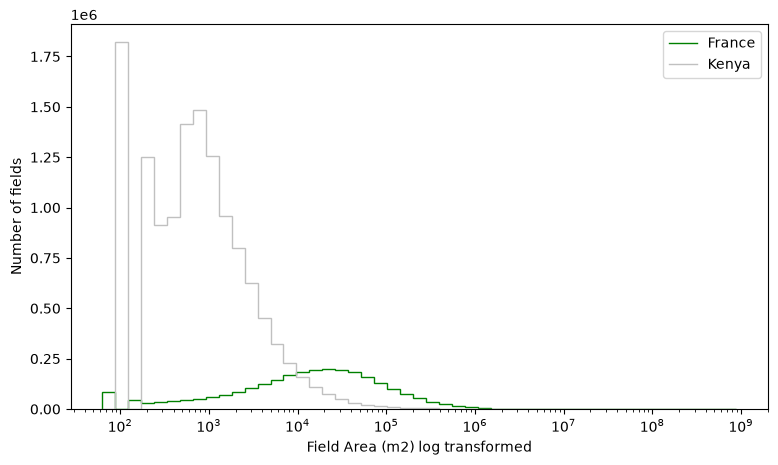

In [14]:
# plot the field distributions
france_areas = field_area_distribution(france24)
kenya_areas = field_area_distribution(kenya24)

# plot a histogram
import numpy as np
import matplotlib.pyplot as plt
import dask
import dask.array as da

fr_min, fr_max, ke_min, ke_max = dask.compute(
    france_areas.min(),
    france_areas.max(),
    kenya_areas.min(),
    kenya_areas.max()
)

min_area = min(fr_min, ke_min)
max_area = max(fr_max, ke_max)

bins = np.logspace(
    np.log10(min_area),
    np.log10(max_area),
    50
)

fr_counts, _ = da.histogram(
    france_areas.to_dask_array(lengths=True),
    bins=bins
)

ke_counts, _ = da.histogram(
    kenya_areas.to_dask_array(lengths=True),
    bins=bins
)

 # compute histogram counts
fr_counts, ke_counts = dask.compute(fr_counts, ke_counts)

# plot both distributions
fig, ax = plt.subplots(figsize=(9, 5))

ax.stairs(fr_counts, bins, label="France", color="green")
ax.stairs(ke_counts, bins, label="Kenya", color="silver")

# plot france and kenya distributions of field area
ax.set_xscale("log")
ax.set_xlabel("Field Area (m2) log transformed")
ax.set_ylabel("Number of fields")
ax.legend()
plt.show()